In [1]:
pip install pandas==2.2.3

Note: you may need to restart the kernel to use updated packages.


In [2]:
pip install matplotlib==3.10.0

Note: you may need to restart the kernel to use updated packages.


In [3]:
pip install seaborn==0.13.2

Note: you may need to restart the kernel to use updated packages.


In [4]:
import pandas as pd

from IPython.display import display, HTML
display(HTML("<style>.container { width:150% !important; }</style>"))
pd.options.display.max_columns=400
pd.options.display.max_rows=8000

import matplotlib.pyplot as plt
import seaborn as sns

In [5]:
df_outages = pd.read_csv("data/outage_report_summaries.csv")
df_services = pd.read_csv("data/cloud_service_risk_ratings.csv")
# Filter first dummy record of file
df_services = df_services[df_services['service_provider'].str.contains('BAD CLOUD EXAMPLE') == False]

In [6]:
#df_outages

In [7]:
#df_services

In [8]:
df_outages1 = df_outages[df_outages['cloud_provider'].str.contains('AWS|GCP|Azure|MongoDB|IBM|Oracle') == False] # Exclude to view  not in != Oracle 
df_outages1

,outage_timestamp,source_outage_report,cloud_provider,cloud_service,regions,availability_zones,start_time,end_time,outage_status,impact,duration,duration_minutes,root_cause,resolution,downtime_period,incident_id,affected_components,mitigation_steps,cloudrisk_genai_output


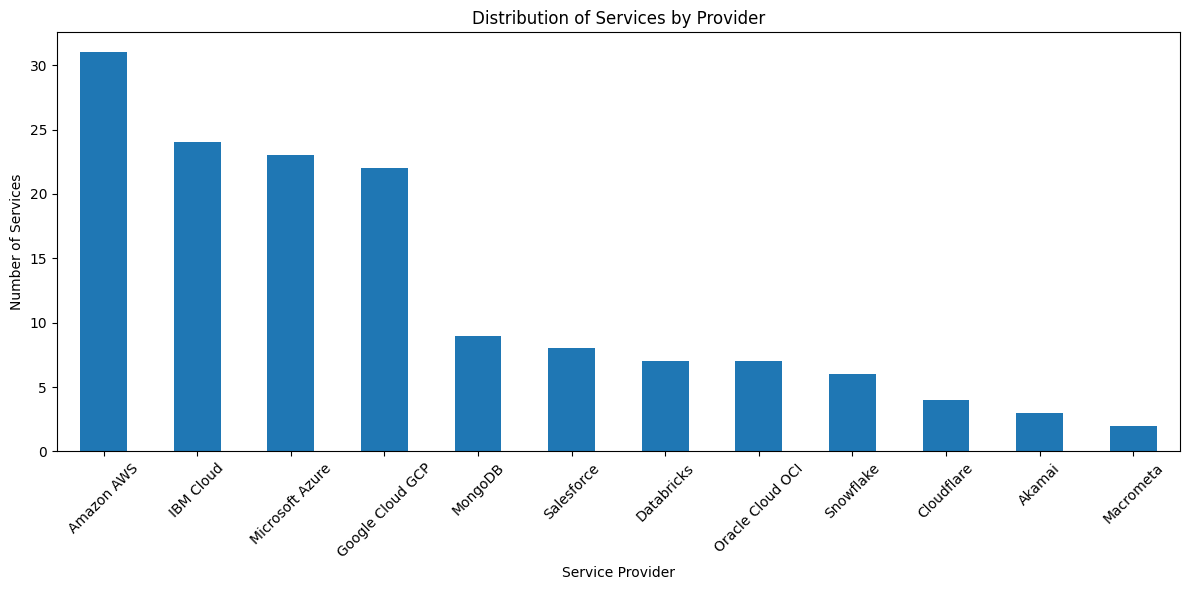

In [9]:
# 1.Service Provider Distribution:
df = df_services
plt.figure(figsize=(12, 6))
df['service_provider'].value_counts().plot(kind='bar')
plt.title('Distribution of Services by Provider')
plt.xlabel('Service Provider')
plt.ylabel('Number of Services')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

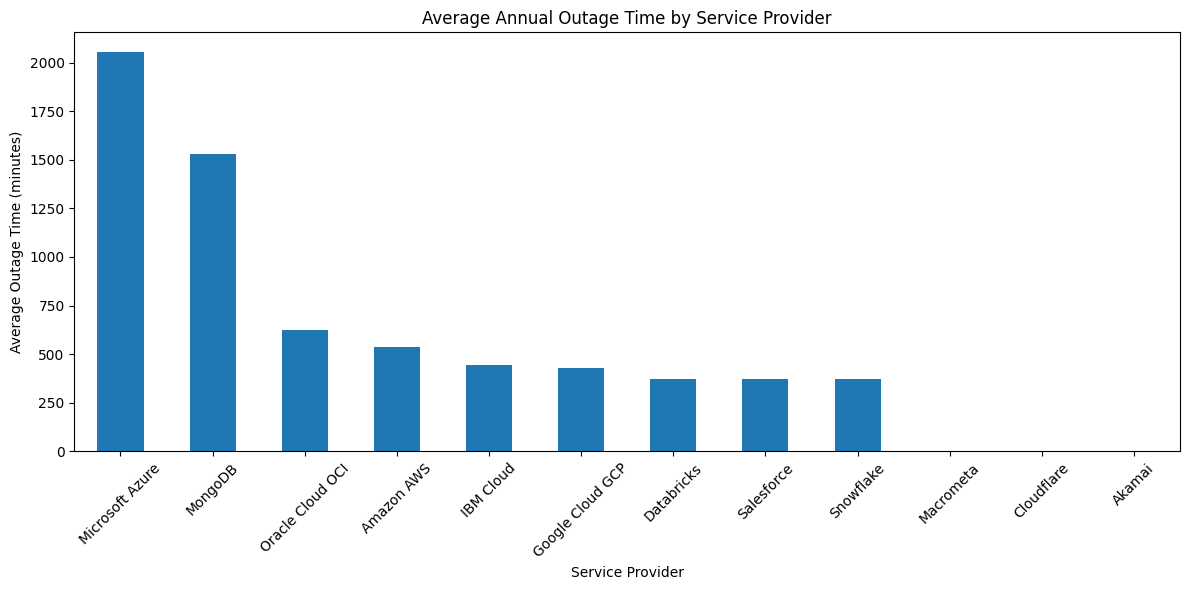

In [10]:
# 2.Average Annual Outage Time by Service Provider:
plt.figure(figsize=(12, 6))
df.groupby('service_provider')['webscraper_annual_period_service_down_per_year_in_minutes'].mean().sort_values(ascending=False).plot(kind='bar')
plt.title('Average Annual Outage Time by Service Provider')
plt.xlabel('Service Provider')
plt.ylabel('Average Outage Time (minutes)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

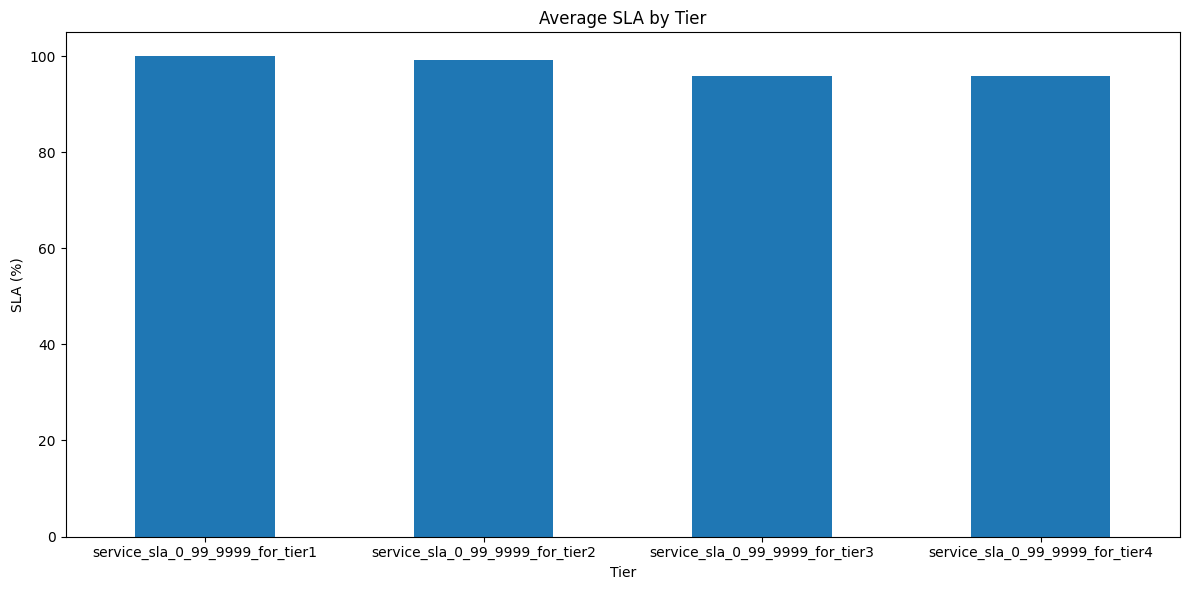

In [11]:
# 3.Service SLA Tiers Comparison:
plt.figure(figsize=(12, 6))
df[['service_sla_0_99_9999_for_tier1', 'service_sla_0_99_9999_for_tier2', 'service_sla_0_99_9999_for_tier3', 'service_sla_0_99_9999_for_tier4']].mean().plot(kind='bar')
plt.title('Average SLA by Tier')
plt.xlabel('Tier')
plt.ylabel('SLA (%)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

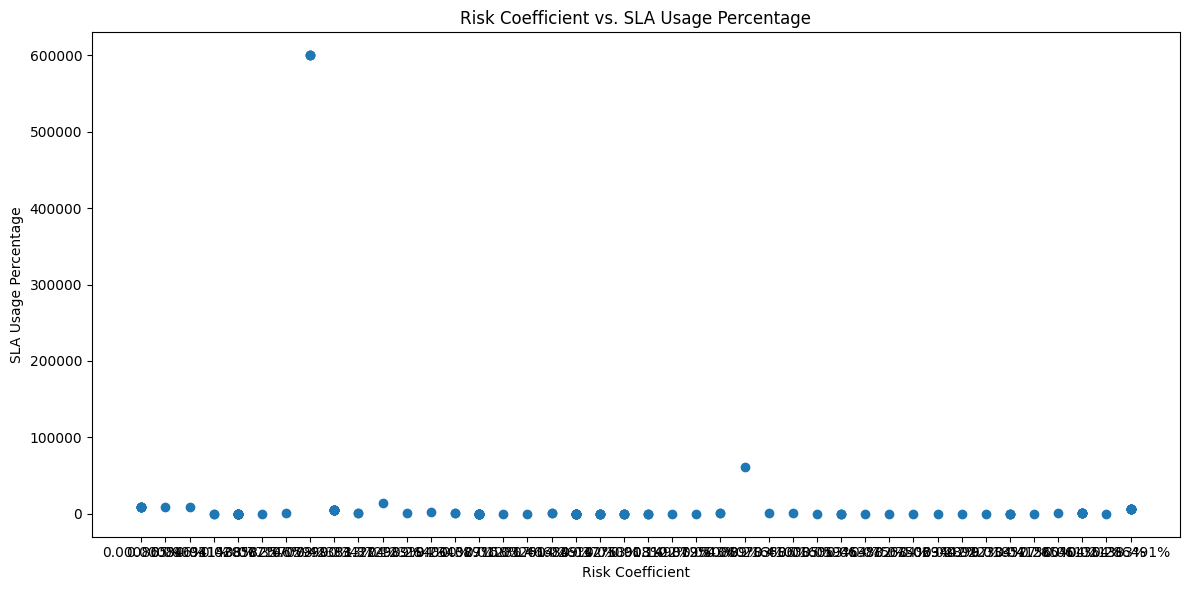

In [12]:
# 4.Risk Coefficient vs. SLA Usage Percentage:
plt.figure(figsize=(12, 6))
plt.scatter(df['riskcoef_per_service_from_gap_expected_actual_time_down'], df['service_sla_usage_percentage'])
plt.title('Risk Coefficient vs. SLA Usage Percentage')
plt.xlabel('Risk Coefficient')
plt.ylabel('SLA Usage Percentage')
plt.tight_layout()
plt.show()

In [13]:
# Global
df_outages_dedup = df_outages.drop_duplicates(subset=['outage_timestamp','source_outage_report','cloud_provider','cloud_service','regions']).sort_values(by=['outage_timestamp'])
df_outages_dedup.to_csv('data/new_sorted_outages_dedup.csv', index=False)

In [14]:
df_outages_dedup.head(10)

,outage_timestamp,source_outage_report,cloud_provider,cloud_service,regions,availability_zones,start_time,end_time,outage_status,impact,duration,duration_minutes,root_cause,resolution,downtime_period,incident_id,affected_components,mitigation_steps,cloudrisk_genai_output
1081,1.576085e+09,outages_files/Azure_status_history_Microsoft_A...,Azure,Azure CDN,north america,not specified,2019-12-11T17:24:00+00:00,2019-12-11T21:48:00+00:00,resolved,NaN,4 hours and 24 minutes,264,Staged deployment process,NaN,"17:24-21:48 UTC on December 11, 2019",NaN,Azure CDN,NaN,Source Outage Report: outages_files/Azure_stat...
1078,1.576085e+09,outages_files/Azure_status_history_Microsoft_A...,Azure,Azure Functions,global (except north america),not specified,2019-12-11T17:24:00+00:00,2019-12-11T21:48:00+00:00,resolved,NaN,4 hours and 24 minutes,264,Staged deployment process,NaN,"17:24-21:48 UTC on December 11, 2019",NaN,Azure CDN,NaN,Source Outage Report: outages_files/Azure_stat...
1080,1.576085e+09,outages_files/Azure_status_history_Microsoft_A...,Azure,Azure CDN,global (except north america),not specified,2019-12-11T17:24:00+00:00,2019-12-11T21:48:00+00:00,resolved,NaN,4 hours and 24 minutes,264,Staged deployment process,NaN,"17:24-21:48 UTC on December 11, 2019",NaN,Azure CDN,NaN,Source Outage Report: outages_files/Azure_stat...
1079,1.576085e+09,outages_files/Azure_status_history_Microsoft_A...,Azure,Azure Functions,north america,not specified,2019-12-11T17:24:00+00:00,2019-12-11T21:48:00+00:00,resolved,NaN,4 hours and 24 minutes,264,Staged deployment process,NaN,"17:24-21:48 UTC on December 11, 2019",NaN,Azure CDN,NaN,Source Outage Report: outages_files/Azure_stat...
1068,1.582894e+09,outages_files/Azure_status_history_Microsoft_A...,Azure,Azure Functions,australiaeast,not specified,2020-02-28T12:48:00+00:00,2020-02-28T22:28:00+00:00,investigating,NaN,6 hours and 22 minutes,382,Incorrect configuration change,NaN,19:10 - 22:28 UTC (3 hours and 18 minutes),NaN,Microsoft Azure,NaN,Source Outage Report: outages_files/Azure_stat...
1069,1.582894e+09,outages_files/Azure_status_history_Microsoft_A...,Azure,Azure Functions,chinaeast2,not specified,2020-02-28T12:48:00+00:00,2020-02-28T22:28:00+00:00,investigating,NaN,6 hours and 22 minutes,382,Incorrect configuration change,NaN,19:10 - 22:28 UTC (3 hours and 18 minutes),NaN,Microsoft Azure,NaN,Source Outage Report: outages_files/Azure_stat...
1066,1.582894e+09,outages_files/Azure_status_history_Microsoft_A...,Azure,Azure Functions,swedencentral,not specified,2020-02-28T12:48:00+00:00,2020-02-28T22:28:00+00:00,investigating,NaN,6 hours and 22 minutes,382,Incorrect configuration change,NaN,19:10 - 22:28 UTC (3 hours and 18 minutes),NaN,Microsoft Azure,NaN,Source Outage Report: outages_files/Azure_stat...
1065,1.582894e+09,outages_files/Azure_status_history_Microsoft_A...,Azure,Azure Functions,chinacloudsites.cn,not specified,2020-02-28T12:48:00+00:00,2020-02-28T22:28:00+00:00,investigating,NaN,6 hours and 22 minutes,382,Incorrect configuration change,NaN,19:10 - 22:28 UTC (3 hours and 18 minutes),NaN,Microsoft Azure,NaN,Source Outage Report: outages_files/Azure_stat...
1072,1.582894e+09,outages_files/Azure_status_history_Microsoft_A...,Azure,Azure Functions,norwayeast,not specified,2020-02-28T12:48:00+00:00,2020-02-28T22:28:00+00:00,investigating,NaN,6 hours and 22 minutes,382,Incorrect configuration change,NaN,19:10 - 22:28 UTC (3 hours and 18 minutes),NaN,Microsoft Azure,NaN,Source Outage Report: outages_files/Azure_stat...
1073,1.582894e+09,outages_files/Azure_status_history_Microsoft_A...,Azure,Azure Functions,southafricanorth,not specified,2020-02-28T12:48:00+00:00,2020-02-28T22:28:00+00:00,investigating,NaN,6 hours and 22 minutes,382,Incorrect configuration change,NaN,19:10 - 22:28 UTC (3 hours and 18 minutes),NaN,Microsoft Azure,NaN,Source Outage Report: outages_files/Azure_stat...


In [15]:
df_outages_dedup.tail(10)

,outage_timestamp,source_outage_report,cloud_provider,cloud_service,regions,availability_zones,start_time,end_time,outage_status,impact,duration,duration_minutes,root_cause,resolution,downtime_period,incident_id,affected_components,mitigation_steps,cloudrisk_genai_output
248,1.745258e+09,outages_files/AWS PES - 21 April 2021 - Summar...,AWS,Amazon Elastic Compute Cloud,us-east-1,single availability zone (not specified),2025-04-21T18:00:00+00:00,2025-04-21T00:00:00,resolved,NaN,Approximately 11 hours,660,A subset of EBS volumes in the affected Availa...,NaN,Customers experienced elevated error rates unt...,NaN,"Amazon AWS Direct Connect, Amazon Elastic Comp...",NaN,Source Outage Report: outages_files/AWS PES - ...
939,1.759085e+09,outages_files/Azure_status_history_Microsoft_A...,Azure,Azure Active Directory,west us,not specified,2025-09-28T18:45:00+00:00,2025-01-21T18:45:00+00:00,resolved,NaN,2 hours and 30 minutes,150,Code defect in the Safe Deployment Pr ocess (S...,NaN,2 hours and 30 minutes,NaN,Microsoft Azure,NaN,Source Outage Report: outages_files/Azure_stat...
936,1.759085e+09,outages_files/Azure_status_history_Microsoft_A...,Azure,Azure Functions,west us,not specified,2025-09-28T18:45:00+00:00,2025-01-21T18:45:00+00:00,resolved,NaN,2 hours and 30 minutes,150,Code defect in the Safe Deployment Pr ocess (S...,NaN,2 hours and 30 minutes,NaN,Microsoft Azure,NaN,Source Outage Report: outages_files/Azure_stat...
937,1.759085e+09,outages_files/Azure_status_history_Microsoft_A...,Azure,Azure Active Directory,west us cosmos db,not specified,2025-09-28T18:45:00+00:00,2025-01-21T18:45:00+00:00,resolved,NaN,2 hours and 30 minutes,150,Code defect in the Safe Deployment Pr ocess (S...,NaN,2 hours and 30 minutes,NaN,Microsoft Azure,NaN,Source Outage Report: outages_files/Azure_stat...
938,1.759085e+09,outages_files/Azure_status_history_Microsoft_A...,Azure,Azure Active Directory,westus,not specified,2025-09-28T18:45:00+00:00,2025-01-21T18:45:00+00:00,resolved,NaN,2 hours and 30 minutes,150,Code defect in the Safe Deployment Pr ocess (S...,NaN,2 hours and 30 minutes,NaN,Microsoft Azure,NaN,Source Outage Report: outages_files/Azure_stat...
935,1.759085e+09,outages_files/Azure_status_history_Microsoft_A...,Azure,Azure Functions,westus,not specified,2025-09-28T18:45:00+00:00,2025-01-21T18:45:00+00:00,resolved,NaN,2 hours and 30 minutes,150,Code defect in the Safe Deployment Pr ocess (S...,NaN,2 hours and 30 minutes,NaN,Microsoft Azure,NaN,Source Outage Report: outages_files/Azure_stat...
934,1.759085e+09,outages_files/Azure_status_history_Microsoft_A...,Azure,Azure Functions,west us cosmos db,not specified,2025-09-28T18:45:00+00:00,2025-01-21T18:45:00+00:00,resolved,NaN,2 hours and 30 minutes,150,Code defect in the Safe Deployment Pr ocess (S...,NaN,2 hours and 30 minutes,NaN,Microsoft Azure,NaN,Source Outage Report: outages_files/Azure_stat...
931,1.759085e+09,outages_files/Azure_status_history_Microsoft_A...,Azure,Azure Cosmos DB,west us cosmos db,not specified,2025-09-28T18:45:00+00:00,2025-01-21T18:45:00+00:00,resolved,NaN,2 hours and 30 minutes,150,Code defect in the Safe Deployment Pr ocess (S...,NaN,2 hours and 30 minutes,NaN,Microsoft Azure,NaN,Source Outage Report: outages_files/Azure_stat...
932,1.759085e+09,outages_files/Azure_status_history_Microsoft_A...,Azure,Azure Cosmos DB,westus,not specified,2025-09-28T18:45:00+00:00,2025-01-21T18:45:00+00:00,resolved,NaN,2 hours and 30 minutes,150,Code defect in the Safe Deployment Pr ocess (S...,NaN,2 hours and 30 minutes,NaN,Microsoft Azure,NaN,Source Outage Report: outages_files/Azure_stat...
933,1.759085e+09,outages_files/Azure_status_history_Microsoft_A...,Azure,Azure Cosmos DB,west us,not specified,2025-09-28T18:45:00+00:00,2025-01-21T18:45:00+00:00,resolved,NaN,2 hours and 30 minutes,150,Code defect in the Safe Deployment Pr ocess (S...,NaN,2 hours and 30 minutes,NaN,Microsoft Azure,NaN,Source Outage Report: outages_files/Azure_stat...


In [16]:
print("done!")

done!


In [17]:
exit()